### Dataset

**Descripción:** Esta dataset fue creado para el paper 'From Group to Individual Labels using Deep Features', Kotzias et. al,. KDD 2015. Sition web: Kotzias, D. (2015). Sentiment Labelled Sentences [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C57604.

**Para más informacíon:**
[Ficha técnica](../docs/ficha-tecnica.md)

In [ ]:
#!apt -qq update
#!apt -qq install -y tesseract-ocr tesseract-ocr-spa
"""
Uncommet previews ubuntu installation dependencies if you are running in colab.
We installed this directly using WSL, since we needed root permissions we ran using direct bash
"""

In [ ]:
#!pip -q install pytesseract opencv-python-headless pillow

"""
If running in colab, you can uncomment previous line and execute. This example was run using WSL, so we installed 
dependencies directly using uv as fallow: uv add pytesseract opencv-python-headless pillow

So if you need the dependencies again you can exec: uv async in you command line.
"""

In [22]:
# make models iside src importable here. For uv this does not matter,
# or when using .venv, but does matter when using global
from util import make_dir_modules_importable
make_dir_modules_importable()

#built-in modeules
import importlib
import pandas as pd
from gensim.models import Word2Vec
import networkx as nx
import matplotlib.pyplot as plt
#custom modules
import lab04_05.data as audit_modeule
import lab04_05.data as data_modeule

importlib.reload(data_modeule)
importlib.reload(audit_modeule)

#custom modules types
from lab04_05.data import Data
from lab04_05.audit import Audit



Adding: /mnt/d/Documents/Ciencias de datos/Ciencia de datos 2/PRACTICAS/uasd-ds-2/unidad02/LAB04-05/src to sys.path


In [ ]:
# covnerting .txt file containing data to csv
# https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences

data = Data()
data.tab_separatd_file_to_csv('raw/amazon_cells_labelled.txt', 'processed/amazon_cells_labelled.csv')
data.tab_separatd_file_to_csv('raw/imdb_labelled.txt', 'processed/imdb_labelled.csv')
data.tab_separatd_file_to_csv('raw/yelp_labelled.txt', 'processed/yelp_labelled.csv')

In [10]:
#load data
data = Data()

#reading data
amazon_dataset_file_path = data.get_file_path('processed/amazon_cells_labelled.csv')
amazon_dataset_df = pd.read_csv(amazon_dataset_file_path, sep="|")
amazon_dataset_df.head()

,text,label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [4]:
#audit data
audit = Audit(amazon_dataset_df)
data.validate_dataframe(
    df=amazon_dataset_df,
    text_column="text",
    target_column="label"
)
print(audit)


- columns: ['text', 'label']
- shape: (1000, 2)
- shape: 10
- distribution: 
  label
0    0.5
1    0.5
Name: proportion, dtype: float64
-----------Summary------------------------
        tipo  ausentes
text     str         0
label  int64         0
-----------ongitudes de textos------------
0.00     11.0
0.25     26.0
0.50     48.0
0.75     77.0
1.00    149.0
Name: text, dtype: float64
------------------------------------------



In [5]:
sentences = [data.tokenize(text) for text in amazon_dataset_df["text"].dropna()]
print(sentences[:2])

[['so', 'there', 'is', 'no', 'way', 'for', 'me', 'to', 'plug', 'it', 'in', 'here', 'in', 'the', 'us', 'unless', 'go', 'by', 'converter'], ['good', 'case', 'excellent', 'value']]


In [8]:
model = Word2Vec(sentences, vector_size=60, window=5, min_count=1, workers=1, epochs=30)

In [11]:
ROOT_DIR = data.get_root_directory()
data.create_directory("models")
data.create_directory("reports")
model.save(str(ROOT_DIR / "models/word2vec.model"))

In [17]:
tokens = [token for sentence in sentences for token in sentence]
print(tokens[:10])
coverage = sum(token in model.wv for token in tokens) / max(len(tokens), 1)
print("Vocabulario:", len(model.wv), "Cobertura:", round(coverage, 3))

['so', 'there', 'is', 'no', 'way', 'for', 'me', 'to', 'plug', 'it']
Vocabulario: 1847 Cobertura: 1.0


In [20]:
WORD_TO_SEARCH = "servicio"
WORD_TO_SEARCH = "plug"
if WORD_TO_SEARCH in model.wv:
    print("Vecinos: ", model.wv.most_similar(WORD_TO_SEARCH, topn=min(10, len(model.wv) - 1)))
else:
    print(f"La palabra '{WORD_TO_SEARCH}' no está en el vocabulario")

Vecinos:  [('screen', 0.998231828212738), ('at', 0.998201847076416), ('while', 0.9981346130371094), ('couldn', 0.998124361038208), ('went', 0.9980953931808472), ('off', 0.9980728030204773), ('gets', 0.998055636882782), ('place', 0.998028576374054), ('that', 0.9980146288871765), ('their', 0.9980107545852661)]


Nodos: 34 Aristas: 78
Comunidades: 3 Modularidad: 0.411


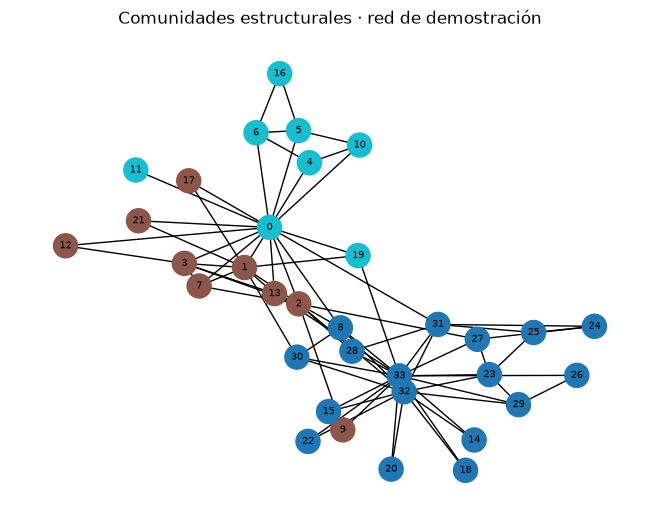

In [23]:
graph = nx.karate_club_graph()
metrics = pd.DataFrame({
    "degree": nx.degree_centrality(graph),
    "betweenness": nx.betweenness_centrality(graph),
    "pagerank": nx.pagerank(graph),
})

metrics.index.name = "node"
metrics.to_csv(ROOT_DIR / "reports/centralities.csv")
communities = list(nx.community.greedy_modularity_communities(graph))
community = {node: index for index, group in enumerate(communities) for node in group}

print("Nodos:", graph.number_of_nodes(), "Aristas:", graph.number_of_edges())
print("Comunidades:", len(communities), "Modularidad:", round(nx.community.modularity(graph, communities), 3))

position = nx.spring_layout(graph, seed=42)
nx.draw(graph, position, node_color=[community[node] for node in graph], cmap="tab10", with_labels=True, font_size=7)
plt.title("Comunidades estructurales · red de demostración")
plt.savefig(ROOT_DIR / "reports/network.png", dpi=180, bbox_inches="tight")
nx.write_graphml(graph, ROOT_DIR / "reports/social_network.graphml")